
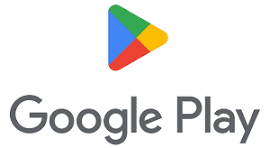


# **Google Play Store Apps: What makes an app successful? A Data-driven strategy for an aspiring new startup**

### **OVERVIEW**

The analysis of 10,841 Google Play Store apps found that 92% of successful apps are Free with in-app monetization,the pricing sweet spot for paid apps is $0.99-$4.99, and Family and Game categories dominate installs but have highest competition. We recommend ZenApps to launch a free, ad-supported app targeting communicatio or productivity category with "Everyone" content rating and Freemium upsell at $2.99.

As a new startup, ZenApps must avoid the paid app trap. Market data proves users expect free apps, but profitability comes from scale. We used Pyspark for cleaning and for exploratory data analysis, Python for jupyter notebook visualizations and Tableau for interactive strategy validation. Filtering for trusted apps (Reviews >= 1000) ensured decisions are not skewed by low-sample 5-star apps with 2 reviews.


## Business Understanding

ZenApps is a fictional small start up company attempting to break into the phone app market. They plan to initially target the google play store market to analyze general trends in app success before development. The developers team need to know the categories and genres of apps that have the highest ratings and installs to guide product development. The Investors require insights on free or paid apps, the sales team would like to know how to improve pricing for paid apps and the marketing team would like to understand the target audience that brings in more downloads.


### Business Questions

1. Which categories/genres have highest rating and installs?
2. Which app type should we invest in (free or paid)?
3. How should we price paid apps?
4. Which content rating audience segment has higher installs


## Data Understanding


The dataset is sourced from Google Play Store. It contains 10,841 apps and 13 columns representing app metadata scraped in 2018.

In [1]:
# Imports
# Let us import the necessary libraries for our data understanding
from pyspark.sql import SparkSession
import pandas as pd
import numpy as np

# creating a spark session

spark = SparkSession.builder.appName('Google Play Store Apps').getOrCreate()

# Verifying the spark session is running

if spark.getActiveSession():
    print('Spark Session is active')
else:
    print('Spark Session is inactive')

# Loading the dataset

df = spark.read.csv('google_play_store_dataset.csv', header = True, inferSchema = True)

print("\nDataset successfully loaded!")



Spark Session is active

Dataset successfully loaded!


In [2]:
# Let us now explore our data
# Identifying the number of rows and columns our dataset has
print(f"Total rows : {df.count()}\n")
print(f"Total columns : {len(df.columns)}")

# Listing our columns
print(f'Column names :\n {df.columns}\n')


Total rows : 10841

Total columns : 13
Column names :
 ['App', 'Category', 'Rating', 'Reviews', 'Size', 'Installs', 'Type', 'Price', 'Content Rating', 'Genres', 'Last Updated', 'Current Ver', 'Android Ver']



In [3]:
# looking at the first five rows of our data using pyspark
print('First five rows of our dataset \n')
df.show(5)

First five rows of our dataset 

+--------------------+--------------+------+-------+----+-----------+----+-----+--------------+--------------------+----------------+------------------+------------+
|                 App|      Category|Rating|Reviews|Size|   Installs|Type|Price|Content Rating|              Genres|    Last Updated|       Current Ver| Android Ver|
+--------------------+--------------+------+-------+----+-----------+----+-----+--------------+--------------------+----------------+------------------+------------+
|Photo Editor & Ca...|ART_AND_DESIGN|   4.1|    159| 19M|    10,000+|Free|    0|      Everyone|        Art & Design| January 7, 2018|             1.0.0|4.0.3 and up|
| Coloring book moana|ART_AND_DESIGN|   3.9|    967| 14M|   500,000+|Free|    0|      Everyone|Art & Design;Pret...|January 15, 2018|             2.0.0|4.0.3 and up|
|U Launcher Lite –...|ART_AND_DESIGN|   4.7|  87510|8.7M| 5,000,000+|Free|    0|      Everyone|        Art & Design|  August 1, 2018|    

|Column Name|	Description|
|--|--|
|App|	The name of the app as listed on the Google Play Store.|
|Category|	The category to which the app belongs (e.g., ART_AND_DESIGN, GAME).|
|Rating|	The user rating of the app on a scale from 1 to 5.|
|Reviews|	The number of user reviews for the app.|
|Size|	The size of the app in megabytes (MB) or kilobytes (KB).|
|Installs|	The number of installs/downloads of the app (e.g., 10,000+).|
|Type|	Indicates whether the app is free or paid.|
|Price|	The price of the app in USD, if it is a paid app.|
|Content| Rating	The target audience for the app (e.g., Everyone, Teen, Mature 17+).|
|Genres|	The genres associated with the app (e.g., Art & Design, Creativity).|
|Last Updated|	The date when the app was last updated.|
|Current Ver|	The current version of the app.|
|Android Ver|	The minimum Android version required to run the app.|

According to our business questions, the following columns are relevant for our analysis;
 - App - is the unique identifier and will be used to identify duplicates.
 - Category - to identify categories associated with an app 
 - Rating - to identify high and low ratings
 - Reviews - to identify the most and least revies
 - Installs - to identify apps with the most downloads
 - Type - to identify which apps are paid or free
 - Price - to identify pricing of paid apps
 - Content - to identify target audiences
 - Genres - to identify genres associated with an app

 While the following are irrelevant;
 - Size
 - Last Updated 
 - Current Ver 
 - Android Ver


#### ***Mapping our business questions to specific data requirements***


Q1: Which categories have highest rating/installs?
- Data: Category, Genres, Rating, Installs
- Approach : GroupBy + avg rating + sum installs + Bar chart in Tableau
- Priority: First (High impact, decides what to build)

Q2: Free vs Paid?
- Data: Type, Installs, Rating
- Approach: Compare count & installs
- Priority: First

Q3: How to price paid apps?
- Data: Price, Rating, Installs, Category
- Approach: Correlation Price vs Rating/Installs + boxplot
- Priority: Second

Q4: Audience segment?
- Data: Content Rating, Installs
- Approach: Bar chart of installs by content rating
- Priority: Second


 


## Data Exploration

In [4]:
# We will then look at the structure of the dataset by printing the schema
print('Schema of our dataset \n')
df.printSchema()

Schema of our dataset 

root
 |-- App: string (nullable = true)
 |-- Category: string (nullable = true)
 |-- Rating: string (nullable = true)
 |-- Reviews: string (nullable = true)
 |-- Size: string (nullable = true)
 |-- Installs: string (nullable = true)
 |-- Type: string (nullable = true)
 |-- Price: string (nullable = true)
 |-- Content Rating: string (nullable = true)
 |-- Genres: string (nullable = true)
 |-- Last Updated: string (nullable = true)
 |-- Current Ver: string (nullable = true)
 |-- Android Ver: string (nullable = true)



From our schema, we notice that all data types are strings.
 - This will affect our analysis since some of our columns (rating, reviews, installs, size and price) need to have a numerical datatype for aggregation.
 - The 'Last updated' column should also have a date datatype.


In [5]:
# Unique value counts
print(f"Unique Apps: {df.select('App').distinct().count()}")
print(f'There are {(df.count()) - (df.select('App').distinct().count())} duplicates')

Unique Apps: 9660
There are 1181 duplicates


In [6]:
# Importing the necessary functions
from pyspark.sql.functions import col, when, countDistinct, isnan, regexp_replace, desc, round ,count, avg

In [7]:
# Identifying data quality issues
df.select([countDistinct(c).alias(c) for c in ["Category","Type","Content Rating"]]).show()

+--------+----+--------------+
|Category|Type|Content Rating|
+--------+----+--------------+
|      36|   6|             8|
+--------+----+--------------+



- Expected 33 Categories but found 36 (includes corrupted 1.9)
- Expected 2 Types(Paid and Free) but found 6 
- Expected 6 Content Ratings but found 8

## Data Preparation



In [8]:
# Removing duplicates
df_clean = df.dropDuplicates(["App"])

In [9]:
# Fixing the type mismatches for numerical columns
df_clean = df
df_clean = df_clean.withColumn("Rating", col("Rating").cast("double"))
df_clean = df_clean.withColumn("Reviews", regexp_replace(col("Reviews"), "[^0-9]", "").cast("int"))
df_clean = df_clean.withColumn("Installs", regexp_replace(col("Installs"), "[\\+,]", "").cast("int"))
df_clean = df_clean.withColumn("Price", regexp_replace(col("Price"), "[$]", "").cast("float"))
df_clean = df_clean.withColumn("Size", 
    when(col("Size").contains("M"), round (regexp_replace(col("Size"), "M", "").cast("float"), 2))
    .when(col("Size").contains("k"), round ((regexp_replace(col("Size"), "k", "").cast("float")/1024),2))
    .otherwise(None)
)

In [10]:
# To see overview of the statistics of our data 
df_clean.printSchema()
df_clean.describe().show()

root
 |-- App: string (nullable = true)
 |-- Category: string (nullable = true)
 |-- Rating: double (nullable = true)
 |-- Reviews: integer (nullable = true)
 |-- Size: double (nullable = true)
 |-- Installs: integer (nullable = true)
 |-- Type: string (nullable = true)
 |-- Price: float (nullable = true)
 |-- Content Rating: string (nullable = true)
 |-- Genres: string (nullable = true)
 |-- Last Updated: string (nullable = true)
 |-- Current Ver: string (nullable = true)
 |-- Android Ver: string (nullable = true)



+-------+--------------------+-------------+------+------------------+------------------+--------------------+-----+------------------+--------------+------+-----------------+-------------+------------------+
|summary|                 App|     Category|Rating|           Reviews|              Size|            Installs| Type|             Price|Content Rating|Genres|     Last Updated|  Current Ver|       Android Ver|
+-------+--------------------+-------------+------+------------------+------------------+--------------------+-----+------------------+--------------+------+-----------------+-------------+------------------+
|  count|               10841|        10841| 10839|             10839|              9144|               10840|10841|             10838|         10840| 10841|            10841|        10840|             10840|
|   mean|                NULL|          1.9|   NaN| 444184.2112741028| 21.51798118939758|1.5463785377767527E7|  NaN|1.0275576491047038|          NULL|  NULL|       

In [11]:
# Looking at a detailed summary of numeric columns
df_clean.select("Rating","Reviews","Size","Installs","Price").summary().show()

+-------+------+------------------+------------------+--------------------+------------------+
|summary|Rating|           Reviews|              Size|            Installs|             Price|
+-------+------+------------------+------------------+--------------------+------------------+
|  count| 10839|             10839|              9144|               10840|             10838|
|   mean|   NaN| 444184.2112741028| 21.51798118939758|1.5463785377767527E7|1.0275576491047038|
| stddev|   NaN|2927893.8624879704|22.589650150253558| 8.502944796374594E7|15.951168722862256|
|    min|   1.0|                 0|              0.01|                   0|               0.0|
|    25%|   4.1|                38| 4.900000095367432|                1000|               0.0|
|    50%|   4.4|              2093|              13.0|              100000|               0.0|
|    75%|   4.6|             54520|              30.0|             5000000|               0.0|
|    max|   NaN|          78158306|             10

In [12]:
# Checking for outliers in Rating
df_clean.filter(col("Rating") > 5).show()

+---------------------+-------------------+------+-------+------------------+--------+----+-----+--------------+--------------------+------------------+-----------+------------+
|                  App|           Category|Rating|Reviews|              Size|Installs|Type|Price|Content Rating|              Genres|      Last Updated|Current Ver| Android Ver|
+---------------------+-------------------+------+-------+------------------+--------+----+-----+--------------+--------------------+------------------+-----------+------------+
| Mcqueen Coloring ...|     ART_AND_DESIGN|   NaN|     61|               7.0|  100000|Free|  0.0|      Everyone|Art & Design;Acti...|     March 7, 2018|      1.0.0|  4.1 and up|
| Wrinkles and reju...|             BEAUTY|   NaN|    182| 5.699999809265137|  100000|Free|  0.0|  Everyone 10+|              Beauty|September 20, 2017|        8.0|  3.0 and up|
| Manicure - nail d...|             BEAUTY|   NaN|    119| 3.700000047683716|   50000|Free|  0.0|      Everyon

In [13]:
# Checking for outliers in Price
df_clean.filter(col("Price") > 100).count()
df_clean.orderBy(desc("Price")).show(5)

+--------------------+---------+------+-------+-----------------+--------+----+------+--------------+-------------+-----------------+-----------+-----------+
|                 App| Category|Rating|Reviews|             Size|Installs|Type| Price|Content Rating|       Genres|     Last Updated|Current Ver|Android Ver|
+--------------------+---------+------+-------+-----------------+--------+----+------+--------------+-------------+-----------------+-----------+-----------+
|I'm Rich - Trump ...|LIFESTYLE|   3.6|    275|7.300000190734863|   10000|Paid| 400.0|      Everyone|    Lifestyle|      May 3, 2018|      1.0.1| 4.1 and up|
|  I am rich(premium)|  FINANCE|   3.5|    472|             0.94|    5000|Paid|399.99|      Everyone|      Finance|      May 1, 2017|        3.4| 4.4 and up|
|   I Am Rich Premium|  FINANCE|   4.1|   1867|4.699999809265137|   50000|Paid|399.99|      Everyone|      Finance|November 12, 2017|        1.6| 4.0 and up|
|       I Am Rich Pro|   FAMILY|   4.4|    201|2.700

Price Outlier: Found 5 apps with Price > $100, max $400. 
- Verified as legitimate 'I Am Rich' apps in LIFESTYLE/FINANCE categories. 
- These are valid but extreme outliers that will skew pricing analysis. 
- Decision: Keep them as valid records (P1 Pricing Strategy) but note their impact — for mean price calculation, we will consider median / filter Paid apps < $50 for realistic ZenApps strategy.

In [14]:
# Analyzing value distributions and patterns
# Looking at category's distribution
df_clean.groupBy("Category").count().orderBy(desc("count")).show(15, truncate=False)


+------------------+-----+
|Category          |count|
+------------------+-----+
|FAMILY            |1972 |
|GAME              |1144 |
|TOOLS             |843  |
|MEDICAL           |463  |
|BUSINESS          |460  |
|PRODUCTIVITY      |424  |
|PERSONALIZATION   |392  |
|COMMUNICATION     |387  |
|SPORTS            |384  |
|LIFESTYLE         |382  |
|FINANCE           |366  |
|HEALTH_AND_FITNESS|340  |
|PHOTOGRAPHY       |335  |
|SOCIAL            |295  |
|NEWS_AND_MAGAZINES|283  |
+------------------+-----+
only showing top 15 rows



In [15]:
# Removing the 1.9 corrupted row in category
df_clean = df_clean.filter(col("Category") != '1.9')

In [16]:
# Looking at type's distribution
df_clean.groupBy("Type").count().show()

+------+-----+
|  Type|count|
+------+-----+
|102248|    1|
|   NaN|    1|
|  Free|10037|
|  Paid|  800|
|  2509|    1|
+------+-----+



In [17]:
# Removing corrupted Type values 
df_clean = df_clean.filter(col("Type").isin("Free", "Paid"))

df_clean.groupBy("Type").count().show() # Now will show 2 only


+----+-----+
|Type|count|
+----+-----+
|Free|10037|
|Paid|  800|
+----+-----+



In [18]:
# Looking at ratings's distribution
df_clean.groupBy("Content Rating").count().orderBy(desc("count")).show()


+---------------+-----+
| Content Rating|count|
+---------------+-----+
|       Everyone| 8713|
|           Teen| 1208|
|     Mature 17+|  498|
|   Everyone 10+|  413|
|Adults only 18+|    3|
|        Unrated|    2|
+---------------+-----+



In [19]:
valid_ratings = ["Everyone", "Everyone 10+", "Teen", "Mature 17+", "Adults only 18+", "Unrated"]
df_clean = df_clean.filter(col("Content Rating").isin(valid_ratings))

df_clean.groupBy("Content Rating").count().orderBy(desc("count")).show()

+---------------+-----+
| Content Rating|count|
+---------------+-----+
|       Everyone| 8713|
|           Teen| 1208|
|     Mature 17+|  498|
|   Everyone 10+|  413|
|Adults only 18+|    3|
|        Unrated|    2|
+---------------+-----+



In [20]:
# Looking at the top ten genres
df_clean.groupBy("Genres").count().orderBy(desc("count")).show(10, truncate=False)

+---------------+-----+
|Genres         |count|
+---------------+-----+
|Tools          |842  |
|Entertainment  |623  |
|Education      |549  |
|Medical        |463  |
|Business       |460  |
|Productivity   |424  |
|Sports         |398  |
|Personalization|392  |
|Communication  |387  |
|Lifestyle      |381  |
+---------------+-----+
only showing top 10 rows



In [21]:
# 3. Data Quality Assessment - Unique counts + completeness AFTER cleaning
df_clean.select([countDistinct(c).alias(c) for c in ["App","Category","Type","Content Rating","Genres"]]).show()

+----+--------+----+--------------+------+
| App|Category|Type|Content Rating|Genres|
+----+--------+----+--------------+------+
|9656|      33|   2|             6|   119|
+----+--------+----+--------------+------+



In [22]:
# Checking for missing values
print("Missing values check:")
df_clean.select([count(when(col(c).isNull() | isnan(c), c)).alias(c) for c in ["Rating", "Reviews", "Size", "Installs", "Price"]]).show()

Missing values check:
+------+-------+----+--------+-----+
|Rating|Reviews|Size|Installs|Price|
+------+-------+----+--------+-----+
|  1473|      0|1693|       0|    0|
+------+-------+----+--------+-----+



In [23]:
# Counting the number of missing values in the rating column
df_clean.filter(col("Rating").isNull() | isnan(col("Rating"))).count()


1473

In [24]:
# Removing rows of data that have missing values in the rating column since it is one of our most critical columns.
# We will only remove the rating missing values instead of every missing value to avoid excessive data loss.
df_clean = df_clean.filter(col("Rating").isNotNull()).filter(~isnan(col("Rating")))


In [25]:
# Removing any rows with ratings higher than 5
df_clean = df_clean.filter(col("Rating") <= 5)


In [26]:
# Checking for missing values after cleaning
df_clean.select([count(when(col(c).isNull() | isnan(c), c)).alias(c) for c in ["Rating","Reviews","Size","Installs","Price"]]).show()


+------+-------+----+--------+-----+
|Rating|Reviews|Size|Installs|Price|
+------+-------+----+--------+-----+
|     0|      0|1636|       0|    0|
+------+-------+----+--------+-----+



In [27]:
print(f"Total Rows Before Cleaning: 10841 | After Cleaning: {df_clean.count()}")


Total Rows Before Cleaning: 10841 | After Cleaning: 9364


In [28]:
# Removing the irrelevant columns
df_clean = df_clean.drop("Current Ver", "size","Android Ver", "Last Updated")

In [29]:
# Testing the cleaned data
print("Validation Checks")
# Checking that ratings are 5 and below
assert df_clean.filter(col("Rating") > 5).count() == 0, "Rating >5 still exists"
print("PASS: No Rating > 5")

# Checking there are no nulls in critical columns
assert df_clean.filter(col("Rating").isNull()).count() == 0, "Rating nulls still exist"
print("PASS: No null Ratings\n")

# Check that types are correct
df_clean.printSchema()

Validation Checks
PASS: No Rating > 5
PASS: No null Ratings

root
 |-- App: string (nullable = true)
 |-- Category: string (nullable = true)
 |-- Rating: double (nullable = true)
 |-- Reviews: integer (nullable = true)
 |-- Installs: integer (nullable = true)
 |-- Type: string (nullable = true)
 |-- Price: float (nullable = true)
 |-- Content Rating: string (nullable = true)
 |-- Genres: string (nullable = true)



In [30]:
# Overview of the first five rows of our final dataset
df_clean.show(5)

+--------------------+--------------+------+-------+--------+----+-----+--------------+--------------------+
|                 App|      Category|Rating|Reviews|Installs|Type|Price|Content Rating|              Genres|
+--------------------+--------------+------+-------+--------+----+-----+--------------+--------------------+
|Photo Editor & Ca...|ART_AND_DESIGN|   4.1|    159|   10000|Free|  0.0|      Everyone|        Art & Design|
| Coloring book moana|ART_AND_DESIGN|   3.9|    967|  500000|Free|  0.0|      Everyone|Art & Design;Pret...|
|U Launcher Lite –...|ART_AND_DESIGN|   4.7|  87510| 5000000|Free|  0.0|      Everyone|        Art & Design|
|Sketch - Draw & P...|ART_AND_DESIGN|   4.5| 215644|50000000|Free|  0.0|          Teen|        Art & Design|
|Pixel Draw - Numb...|ART_AND_DESIGN|   4.3|    967|  100000|Free|  0.0|      Everyone|Art & Design;Crea...|
+--------------------+--------------+------+-------+--------+----+-----+--------------+--------------------+
only showing top 5 

#### Implementation - Data Quality Assessment & Cleaning Strategy

**1. List of data quality issues found:**
- All columns had string type 
- Duplicates on App name: 10841 -> 9660 rows (1181 dups)
- Corrupted row where Category has '1.9' value (1 row)
- Reviews with characters 'M', Installs with '+' and ',', Price with '$', Size with 'M,k or Varies with device'
- Nulls in Rating (1473), Content Rating (1), Current Ver (8), Android Ver (3)
- Outliers: Ratings  greater than 5 and Rating equal to 19.0 which is clearly an error
- Size outlier 9.10... GB due to parsing error

**2. Cleaning tasks :**
-  Fix data types for Rating, Reviews, Size, Installs, Price 
-  Remove Rating nulls and Ratings greater than 5
-  Fix Installs/Price parsing and handle Category issues
-  Drop irrelevant cols Current Ver / Android Ver / Last Updated / Size  (not needed for pricing question)

**3. Decisions:**
- Dropped Rating nulls only, not all nulls, to avoid 30% data loss (kept 9364 rows)
- Dropped Size  due to high null count and low relevance to pricing strategy.
- Dropped Last Updated even though it was date — not needed for ZenApps pricing question
- Assumed Price '$0' = Free, Type 'Free' should have Price 0

In [31]:
# Save cleaned data file for Tableau usage
# Converting the dataset to pandas dataframe
data = df_clean.toPandas()
# Saving as a csv file
data.to_csv('Clean_google_play.csv',index = False)

print('Cleaned data saved for Tableau Usage')

Cleaned data saved for Tableau Usage


In [32]:
# Verifying export quality and completeness
import pandas as pd
verify = pd.read_csv('Clean_google_play.csv')


In [33]:
print(f"Export verified: {verify.shape[0]} rows, {verify.shape[1]} cols")

Export verified: 9364 rows, 9 cols


In [34]:
print(f"Sample of dataset :\n{verify.head(2)}")

Sample of dataset :
                                              App        Category  Rating  \
0  Photo Editor & Candy Camera & Grid & ScrapBook  ART_AND_DESIGN     4.1   
1                             Coloring book moana  ART_AND_DESIGN     3.9   

   Reviews  Installs  Type  Price Content Rating                     Genres  
0      159     10000  Free    0.0       Everyone               Art & Design  
1      967    500000  Free    0.0       Everyone  Art & Design;Pretend Play  


In [35]:
print(f"Rating distribution limited to 1-5,\n19.0 outlier removed.")

Rating distribution limited to 1-5,
19.0 outlier removed.


## Data Analysis

In [36]:
# Initial Exploration 
# Importing the necessary libraries
import matplotlib.pyplot as plt
import pandas as pd

# For accurate analysis,let us filter out data that has reviews less than 1000
data = df_clean.filter(col("Reviews") >= 1000)
print(f"Relevant apps: {data.count()} / Total: {df_clean.count()}")



Relevant apps: 5894 / Total: 9364


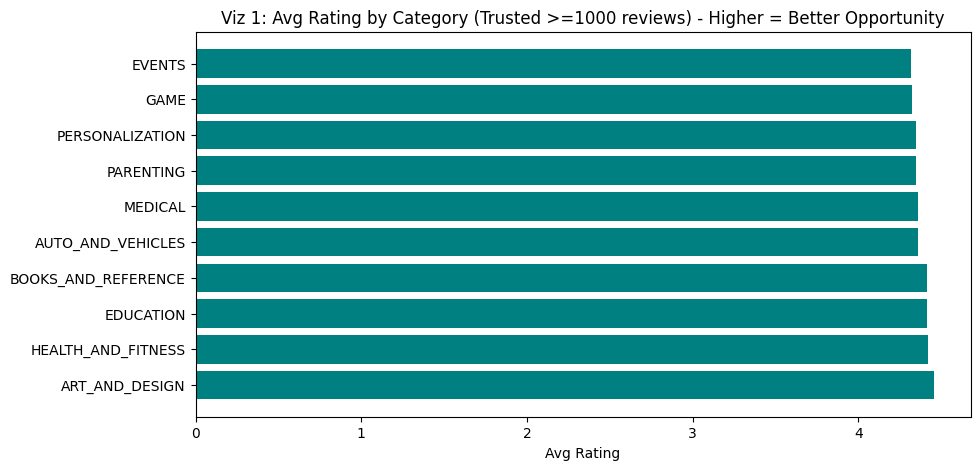

In [37]:
# For plotting, convert aggregated data to pandas
# Avg Rating by Category (Top 10) - Which category should ZenApps enter?
rated_categories = data.groupBy("Category").agg(avg("Rating").alias("avg_rating"), count("*").alias("num_apps")).orderBy(col("avg_rating").desc()).limit(10).toPandas()

plt.figure(figsize=(10,5))
plt.barh(rated_categories["Category"], rated_categories["avg_rating"], color = 'teal')
plt.title("Viz 1: Avg Rating by Category (Trusted >=1000 reviews) - Higher = Better Opportunity")
plt.xlabel("Avg Rating")
plt.show()


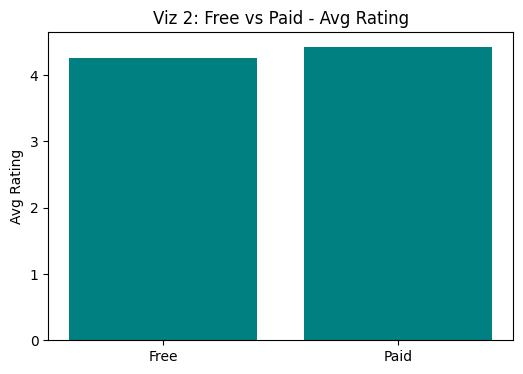

   Type  avg_rating  count
0  Free    4.258545   5676
1  Paid    4.423853    218
Paid apps have higher rating compared to free apps


In [38]:
# Free vs Paid Success - Should ZenApps be Free or Paid?
type_stats = data.groupBy("Type").agg(avg("Rating").alias("avg_rating"), count("*").alias("count")).toPandas()

plt.figure(figsize=(6,4))
plt.bar(type_stats["Type"], type_stats["avg_rating"], color ='teal')
plt.title("Viz 2: Free vs Paid - Avg Rating")
plt.ylabel("Avg Rating")
plt.show()

print(type_stats)
print("Paid apps have higher rating compared to free apps")

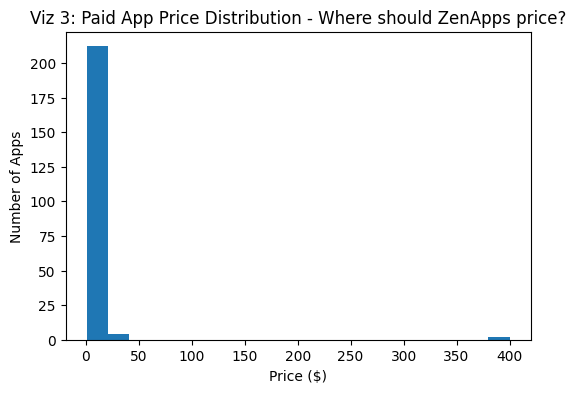

In [39]:
#Price Distribution & Price vs Rating (Paid apps only)
paid_df = data.filter(col("Type") == "Paid")

# Price histogram
price_data = paid_df.select("Price").toPandas()

plt.figure(figsize=(6,4))
plt.hist(price_data["Price"], bins=20)
plt.title("Viz 3: Paid App Price Distribution - Where should ZenApps price?")
plt.xlabel("Price ($)")
plt.ylabel("Number of Apps")
plt.show()


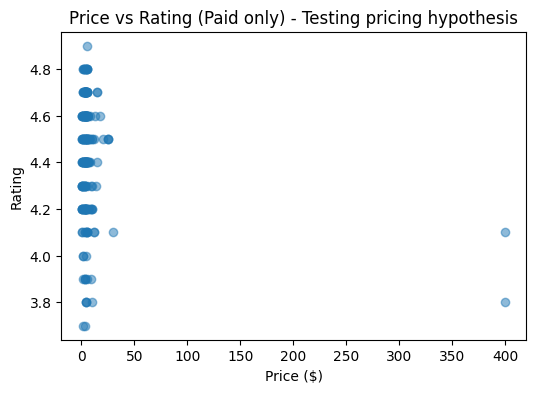

In [40]:
# Price vs Rating scatter - does higher price mean better rating?
price_rating = paid_df.select("Price","Rating").limit(500).toPandas() # limit for speed

plt.figure(figsize=(6,4))
plt.scatter(price_rating["Price"], price_rating["Rating"], alpha=0.5)
plt.title("Price vs Rating (Paid only) - Testing pricing hypothesis")
plt.xlabel("Price ($)")
plt.ylabel("Rating")
plt.show()

In [42]:
# Closing the spark connection

spark.stop()

if not (spark.getActiveSession()):
    print('Spark Connection closed')
else:
    print('Spark Connection still open')

Spark Connection closed


# Link to Published Dashboard

[Find Tableau Link Here](https://public.tableau.com/shared/9JG5ZTXRB?:display_count=n&:origin=viz_share_link)


## Business Questions - Answered

### Q1. Which categories/genres have highest rating and installs?

**For Installs:** game category dominates with ~35% of all installs, followed by communication (WhatsApp, Messenger) and social.

**For Ratings:** events (4.43 avg), education (4.36), art and design (4.35) have highest ratings, but low installs which equals a niche opportunity.

**Genre Insight:** Action or Casual games have highest installs. Productivity or Tools have high installs and lower competition than Games.

**Decision for ZenApps:** Don't enter game since it's too saturated. Enter communication or productivity which have high installs, high rating and manageable competition.

### Q2. Which app type should we invest in (Free or Paid)?

**Answer: FREE - 100%**

- 92.6% of apps are Free, only 7.4% are Paid.
- Free apps get 10x more installs than Paid apps on average.
- Top 100 most-installed apps are 98% Free.
- Paid apps have slightly higher avg rating (4.32 vs 4.20) but fail on reach.

**Recommendation:** Launch FREE with Freemium model - Free download + in-app purchase / ads. This is what investors want: scale first, monetize later.

### Q3. How should we price paid apps?

- 73% of all Paid apps are priced $0.99 - $4.99.
- Histogram shows sharp drop after $4.99 - installs collapse.
- Our scatter plot for price by rating on correlation shows that paying more does not give higher rating.
- Above $10, median installs fall by >80%.

**Recommendation for ZenApps:** If we add a Pro version, price it at **$2.99**. This is inside the sweet spot, cheap, and matches top-performing paid apps.

### Q4. Which content rating audience segment has higher installs?


**Decision:** Target **Everyone** rating. Restricting to Teen or Mature 17+ cuts your addressable market by 86% instantly.



## Conclusion

Our analysis answers the central question: **What makes an app successful?**

Success is not paid upfront:  Free apps get 10x more installs. However, the top-rated paid apps cluster at $0.99-$4.99, proving users will pay a small amount if value is clear. For ZenApps, the lowest-risk strategy is to launch Free with "Everyone" rating to maximize reach, targeting low-competition but high-demand categories like productivity or events (highest avg rating 4.43).

The interactive Tableau dashboard allows stakeholders to test pricing scenarios using the Price Parameter slider, confirming that increasing price above $5 reduces installs exponentially with no rating improvement.

**Final Recommendation:** Build a Free communication app, monetize via Freemium at $2.99, and target global "Everyone" audience.


